In [1]:

print("FetalVision - Head Detection")
print("Python is working!")


FetalVision - Head Detection
Python is working!


In [4]:

from google.colab import files

uploaded = files.upload()


Saving 1_HC.png to 1_HC.png
Saving 1_HC_Annotation.png to 1_HC_Annotation.png


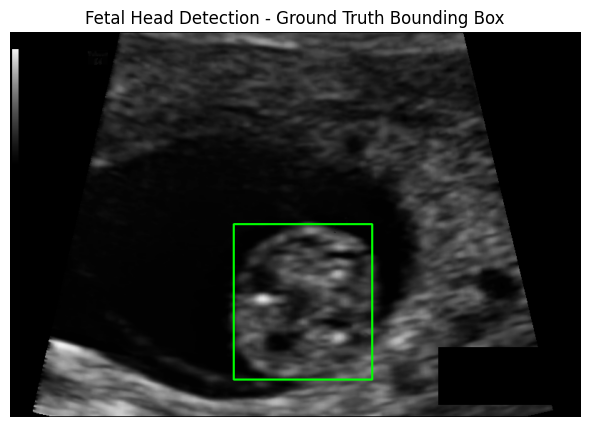

Bounding Box: 313 269 194 218


In [5]:

import cv2
import matplotlib.pyplot as plt

# Read ultrasound image and annotation
image = cv2.imread("1_HC.png")
mask = cv2.imread("1_HC_Annotation.png", 0)

# Find the white ellipse in the annotation
_, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

# Find the bounding box around the ellipse
x, y, w, h = cv2.boundingRect(binary)

# Draw the box on the original image
result = image.copy()
cv2.rectangle(result, (x, y), (x+w, y+h), (0, 255, 0), 2)

# Display the result
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Fetal Head Detection - Ground Truth Bounding Box")
plt.axis("off")
plt.show()

print("Bounding Box:", x, y, w, h)


In [6]:

# Get original image dimensions
image_height, image_width = image.shape[:2]

# Calculate box center
x_center = x + w / 2
y_center = y + h / 2

# Normalize coordinates for YOLO
x_center_norm = x_center / image_width
y_center_norm = y_center / image_height
w_norm = w / image_width
h_norm = h / image_height

# Class 0 = fetal head
class_id = 0

yolo_label = (
    f"{class_id} {x_center_norm:.6f} "
    f"{y_center_norm:.6f} {w_norm:.6f} {h_norm:.6f}"
)

print("Image size:", image_width, "x", image_height)
print("YOLO label:", yolo_label)


Image size: 800 x 540
YOLO label: 0 0.512500 0.700000 0.242500 0.403704


In [7]:

# Save the YOLO annotation
with open("1_HC.txt", "w") as f:
    f.write(yolo_label + "\n")

# Verify the saved label
with open("1_HC.txt", "r") as f:
    print(f.read())

print("YOLO label saved successfully!")


0 0.512500 0.700000 0.242500 0.403704

YOLO label saved successfully!


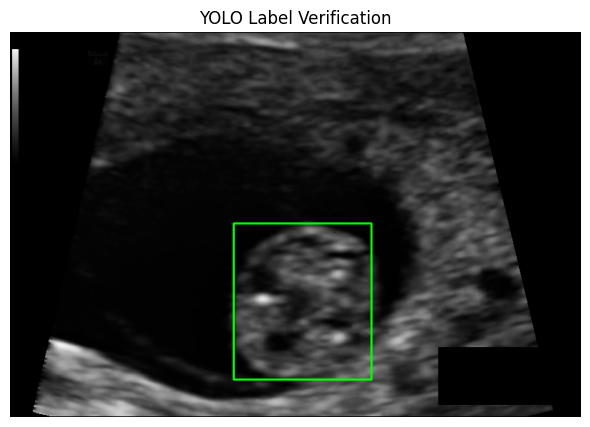

Class: 0
Box: 313 268 506 487


In [8]:

# Read the saved YOLO label
with open("1_HC.txt", "r") as f:
    values = f.read().split()

class_id = int(values[0])
xc, yc, bw, bh = map(float, values[1:])

# Convert normalized coordinates back to pixels
x1 = int((xc - bw / 2) * image_width)
y1 = int((yc - bh / 2) * image_height)
x2 = int((xc + bw / 2) * image_width)
y2 = int((yc + bh / 2) * image_height)

# Draw the reconstructed bounding box
check_image = image.copy()
cv2.rectangle(check_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(check_image, cv2.COLOR_BGR2RGB))
plt.title("YOLO Label Verification")
plt.axis("off")
plt.show()

print("Class:", class_id)
print("Box:", x1, y1, x2, y2)


In [10]:

from google.colab import files

uploaded_zip = files.upload()


Saving training_set.zip to training_set.zip


In [11]:

import zipfile
import os

# Extract the dataset
with zipfile.ZipFile("training_set.zip", "r") as zip_ref:
    zip_ref.extractall("/content/HC18")

# Check extracted files
for root, dirs, files in os.walk("/content/HC18"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("First 10 files:", files[:10])
    break


Folder: /content/HC18
Number of files: 0
First 10 files: []


In [12]:

import os

for root, dirs, files in os.walk("/content/HC18"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("First 5 files:", files[:5])
    print("----------------------")


Folder: /content/HC18
Number of files: 0
First 5 files: []
----------------------
Folder: /content/HC18/training_set
Number of files: 1999
First 5 files: ['52_HC.png', '528_HC.png', '743_HC.png', '773_HC.png', '770_HC.png']
----------------------


In [14]:

from pathlib import Path

data_dir = Path("/content/HC18/training_set")

all_files = list(data_dir.iterdir())

images = [
    f for f in all_files
    if f.name.endswith("HC.png") and "_Annotation" not in f.name
]

annotations = [
    f for f in all_files
    if f.name.endswith("_Annotation.png")
]

other_files = [
    f.name for f in all_files
    if f not in images and f not in annotations
]

print("Total files:", len(all_files))
print("Ultrasound images:", len(images))
print("Annotations:", len(annotations))
print("Other files:", other_files)


Total files: 1999
Ultrasound images: 999
Annotations: 999
Other files: ['Thumbs.db']


In [17]:

from pathlib import Path

data_dir = Path("/content/HC18/training_set")

missing_annotations = []

for img_path in images:
    annotation_path = data_dir / (
        img_path.stem + "_Annotation.png"
    )

    if not annotation_path.exists():
        missing_annotations.append(img_path.name)

print("Images checked:", len(images))
print("Missing annotations:", len(missing_annotations))
print("Examples:", missing_annotations[:10])


Images checked: 999
Missing annotations: 0
Examples: []


In [18]:

import cv2
import csv
from pathlib import Path

data_dir = Path("/content/HC18/training_set")
labels_dir = Path("/content/HC18/yolo_labels")
labels_dir.mkdir(parents=True, exist_ok=True)

converted = 0
errors = []

for img_path in sorted(images):
    annotation_path = data_dir / (img_path.stem + "_Annotation.png")

    img = cv2.imread(str(img_path))
    mask = cv2.imread(str(annotation_path), cv2.IMREAD_GRAYSCALE)

    if img is None or mask is None:
        errors.append((img_path.name, "Cannot read image or annotation"))
        continue

    H, W = img.shape[:2]

    if mask.shape[:2] != (H, W):
        errors.append((img_path.name, "Image and annotation sizes differ"))
        continue

    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    x, y, w, h = cv2.boundingRect(binary)

    if w == 0 or h == 0:
        errors.append((img_path.name, "Empty annotation"))
        continue

    xc = (x + w / 2) / W
    yc = (y + h / 2) / H
    wn = w / W
    hn = h / H

    label = f"0 {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}\n"
    (labels_dir / (img_path.stem + ".txt")).write_text(label)

    converted += 1

print("Images processed:", len(images))
print("YOLO labels created:", converted)
print("Errors:", len(errors))
print("First errors:", errors[:10])


Images processed: 999
YOLO labels created: 999
Errors: 0
First errors: []


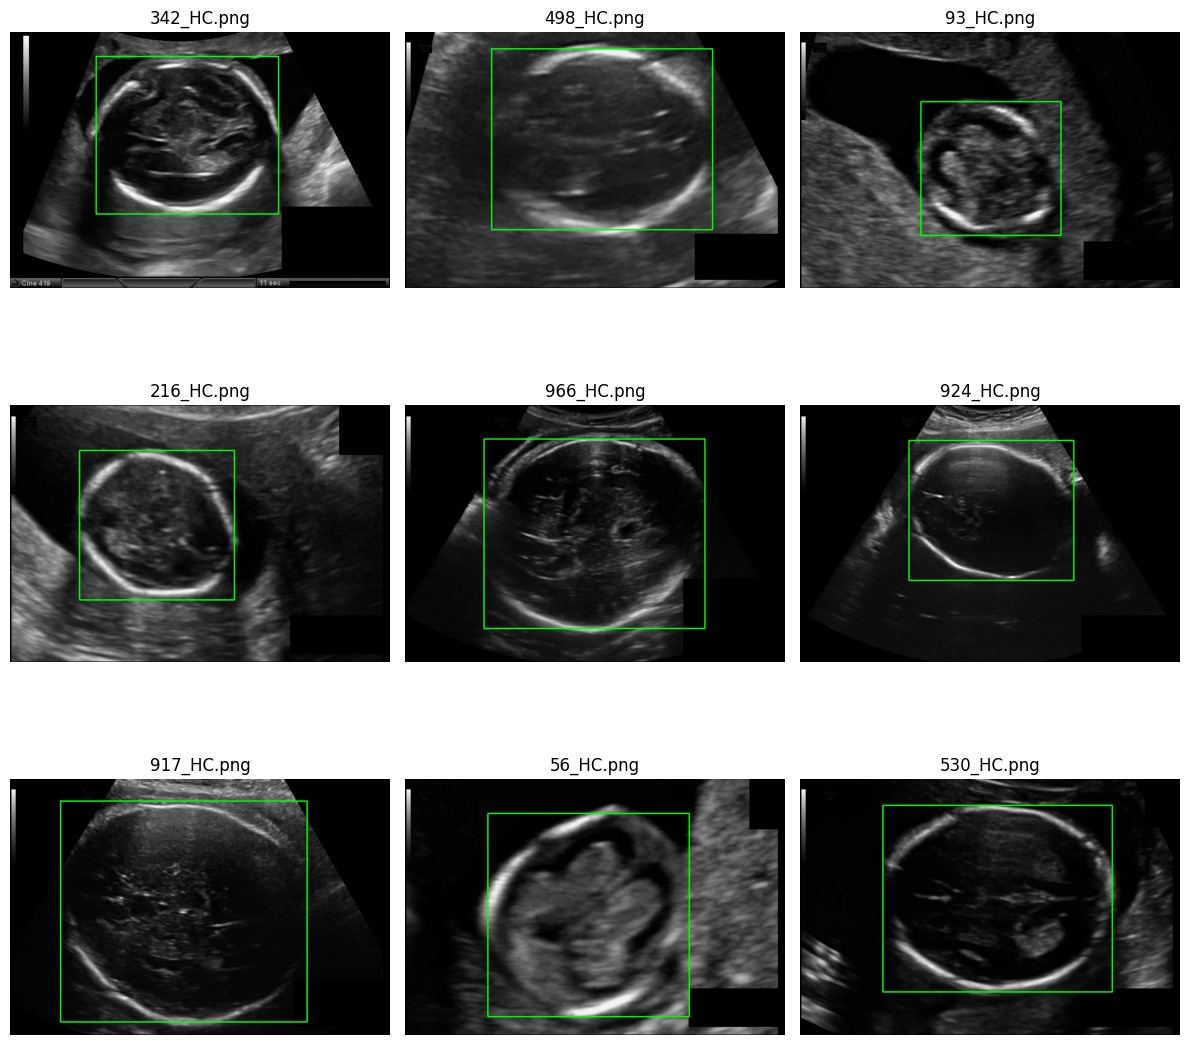

In [19]:

import random
import cv2
import matplotlib.pyplot as plt

# Select 9 random images
random.seed(42)
samples = random.sample(images, 9)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, img_path in zip(axes.flat, samples):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]

    label_path = labels_dir / (img_path.stem + ".txt")

    values = label_path.read_text().split()
    xc, yc, bw, bh = map(float, values[1:])

    x1 = round((xc - bw / 2) * W)
    y1 = round((yc - bh / 2) * H)
    x2 = round((xc + bw / 2) * W)
    y2 = round((yc + bh / 2) * H)

    cv2.rectangle(
        img, (x1, y1), (x2, y2),
        (0, 255, 0), 2
    )

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [20]:

import shutil
from google.colab import files

# Create a ZIP archive containing all YOLO labels
shutil.make_archive(
    "/content/FetalVision_YOLO_Labels",
    "zip",
    "/content/HC18",
    "yolo_labels"
)

# Download a copy to your computer
files.download("/content/FetalVision_YOLO_Labels.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

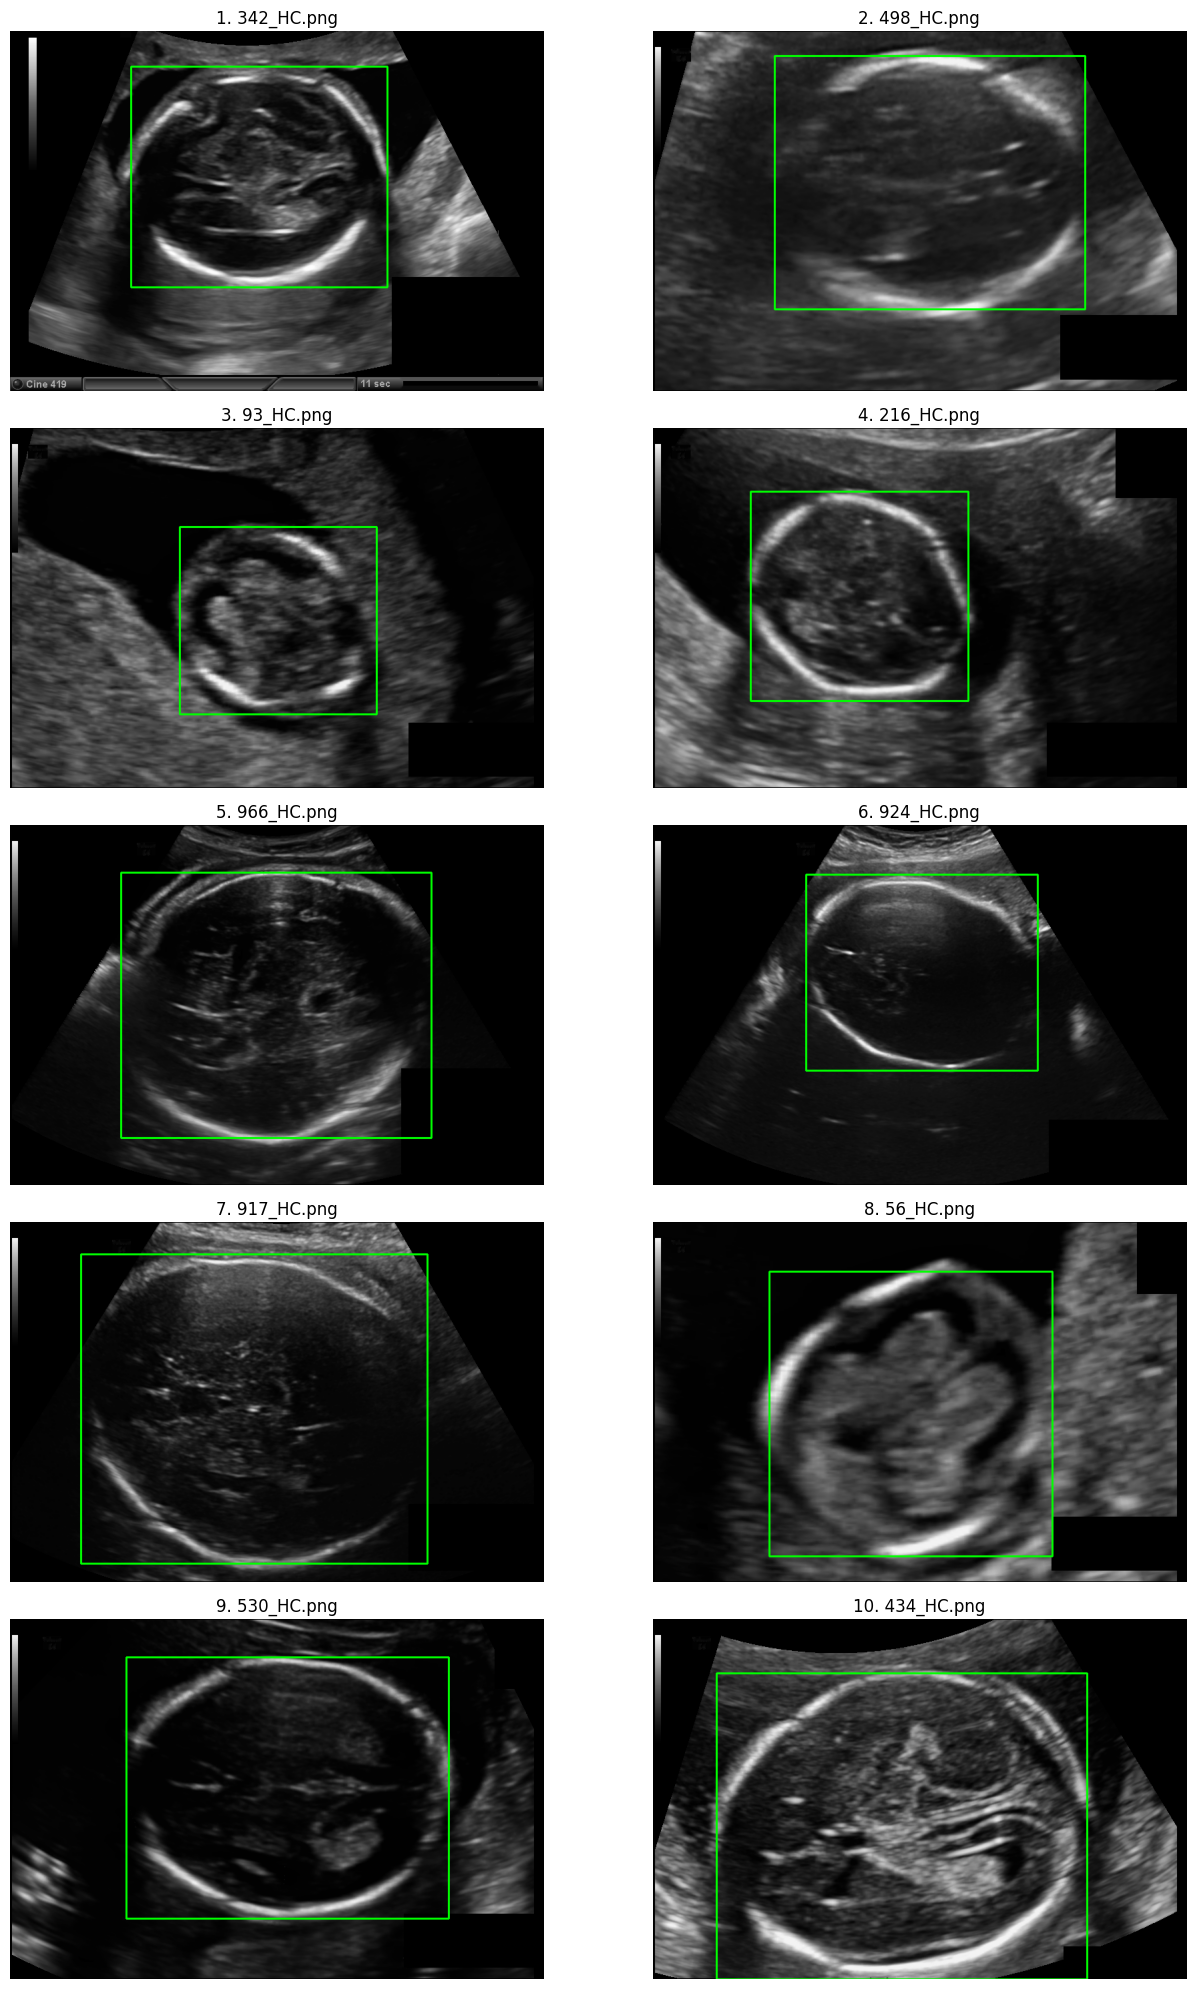

In [21]:

import random
import cv2
import matplotlib.pyplot as plt

# Select 30 reproducible random samples
random.seed(42)
review_samples = random.sample(images, 30)

# Show first 10 images
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, (ax, img_path) in enumerate(
    zip(axes.flat, review_samples[:10])
):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]

    label_path = labels_dir / (img_path.stem + ".txt")
    values = label_path.read_text().split()
    xc, yc, bw, bh = map(float, values[1:])

    x1 = round((xc - bw / 2) * W)
    y1 = round((yc - bh / 2) * H)
    x2 = round((xc + bw / 2) * W)
    y2 = round((yc + bh / 2) * H)

    cv2.rectangle(
        img, (x1, y1), (x2, y2),
        (0, 255, 0), 2
    )

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{i+1}. {img_path.name}", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()


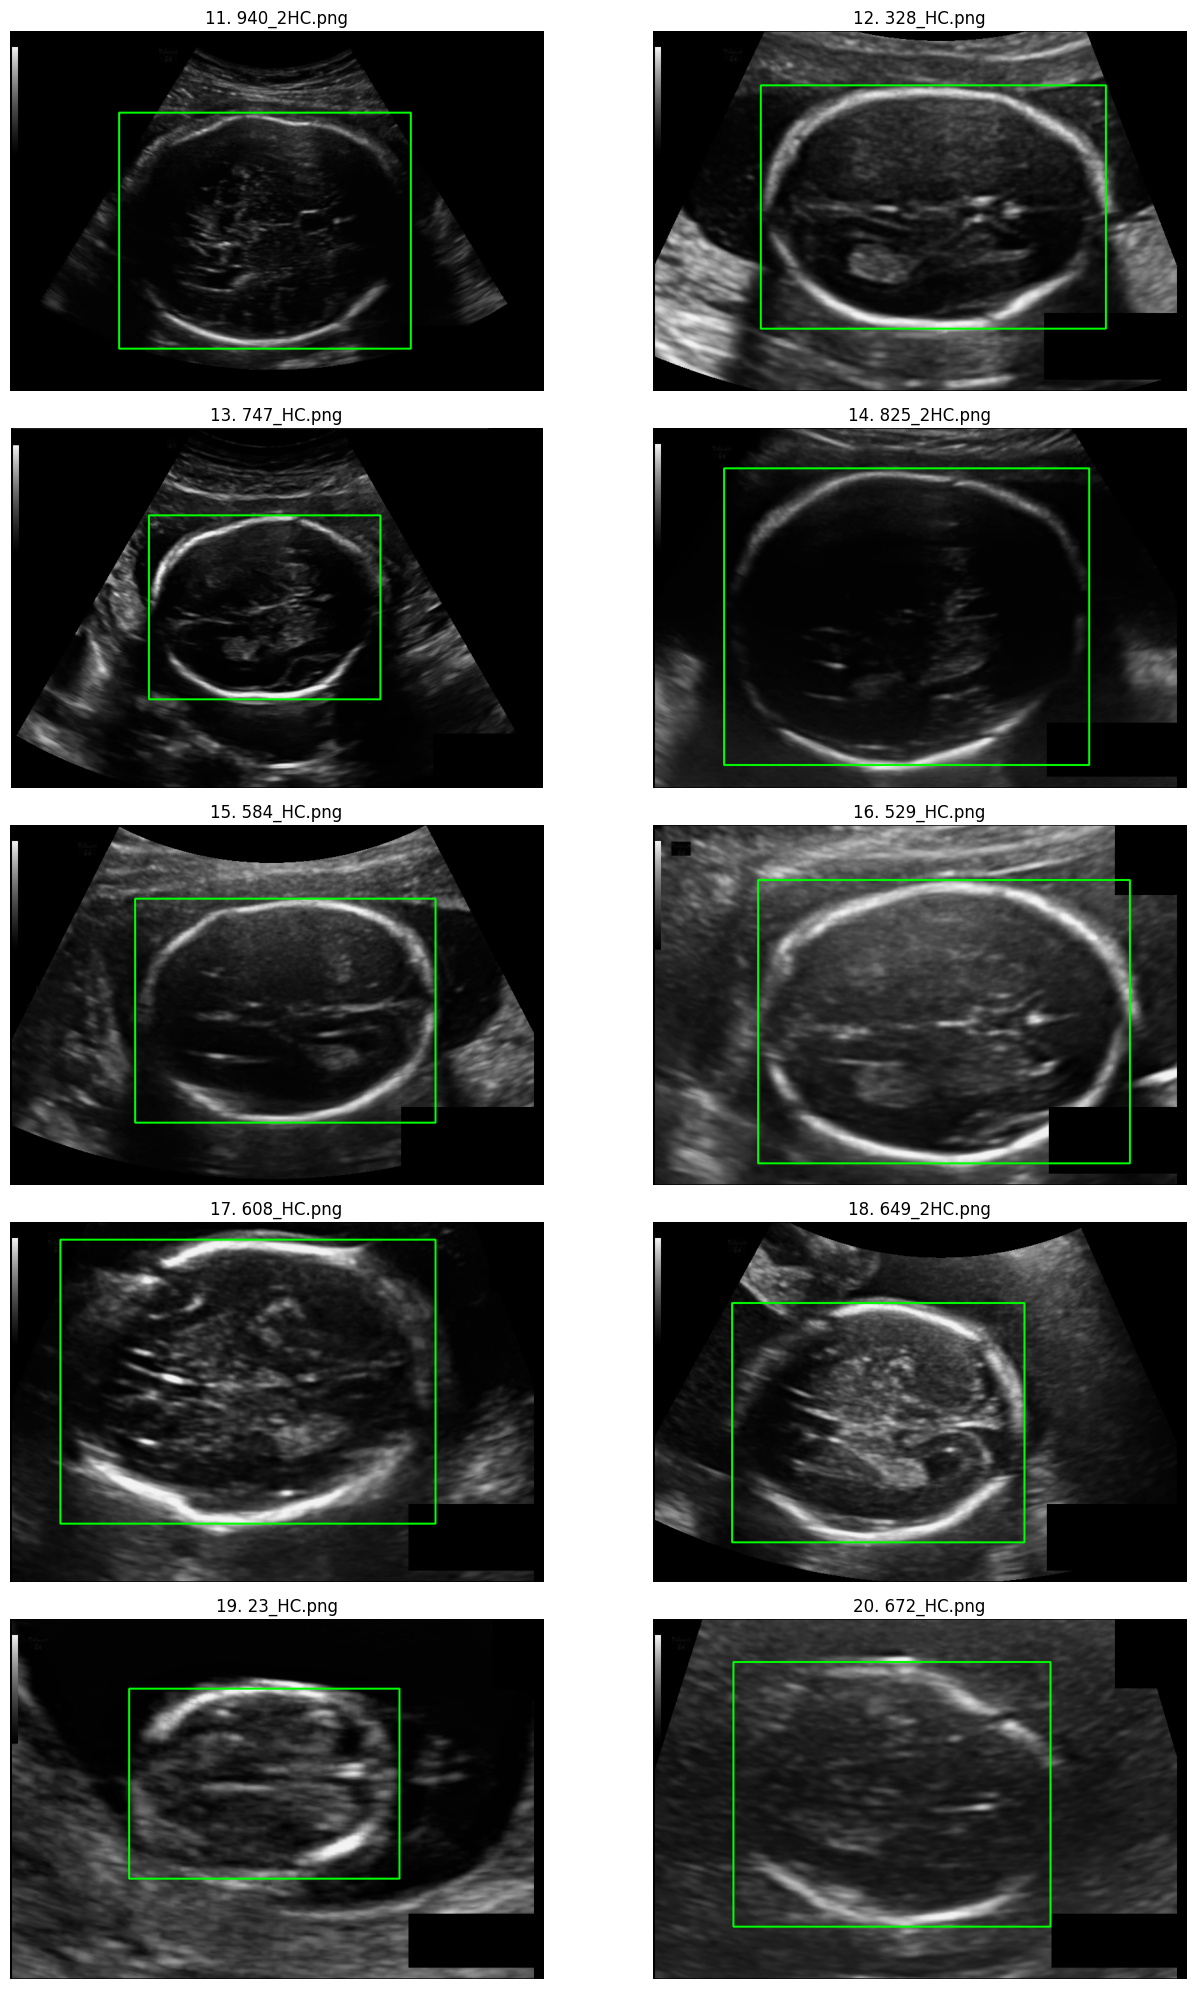

In [22]:

# Visual review: images 11 to 20

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, (ax, img_path) in enumerate(
    zip(axes.flat, review_samples[10:20]), start=11
):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]

    label_path = labels_dir / (img_path.stem + ".txt")
    values = label_path.read_text().split()

    xc, yc, bw, bh = map(float, values[1:])

    x1 = round((xc - bw / 2) * W)
    y1 = round((yc - bh / 2) * H)
    x2 = round((xc + bw / 2) * W)
    y2 = round((yc + bh / 2) * H)

    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{i}. {img_path.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


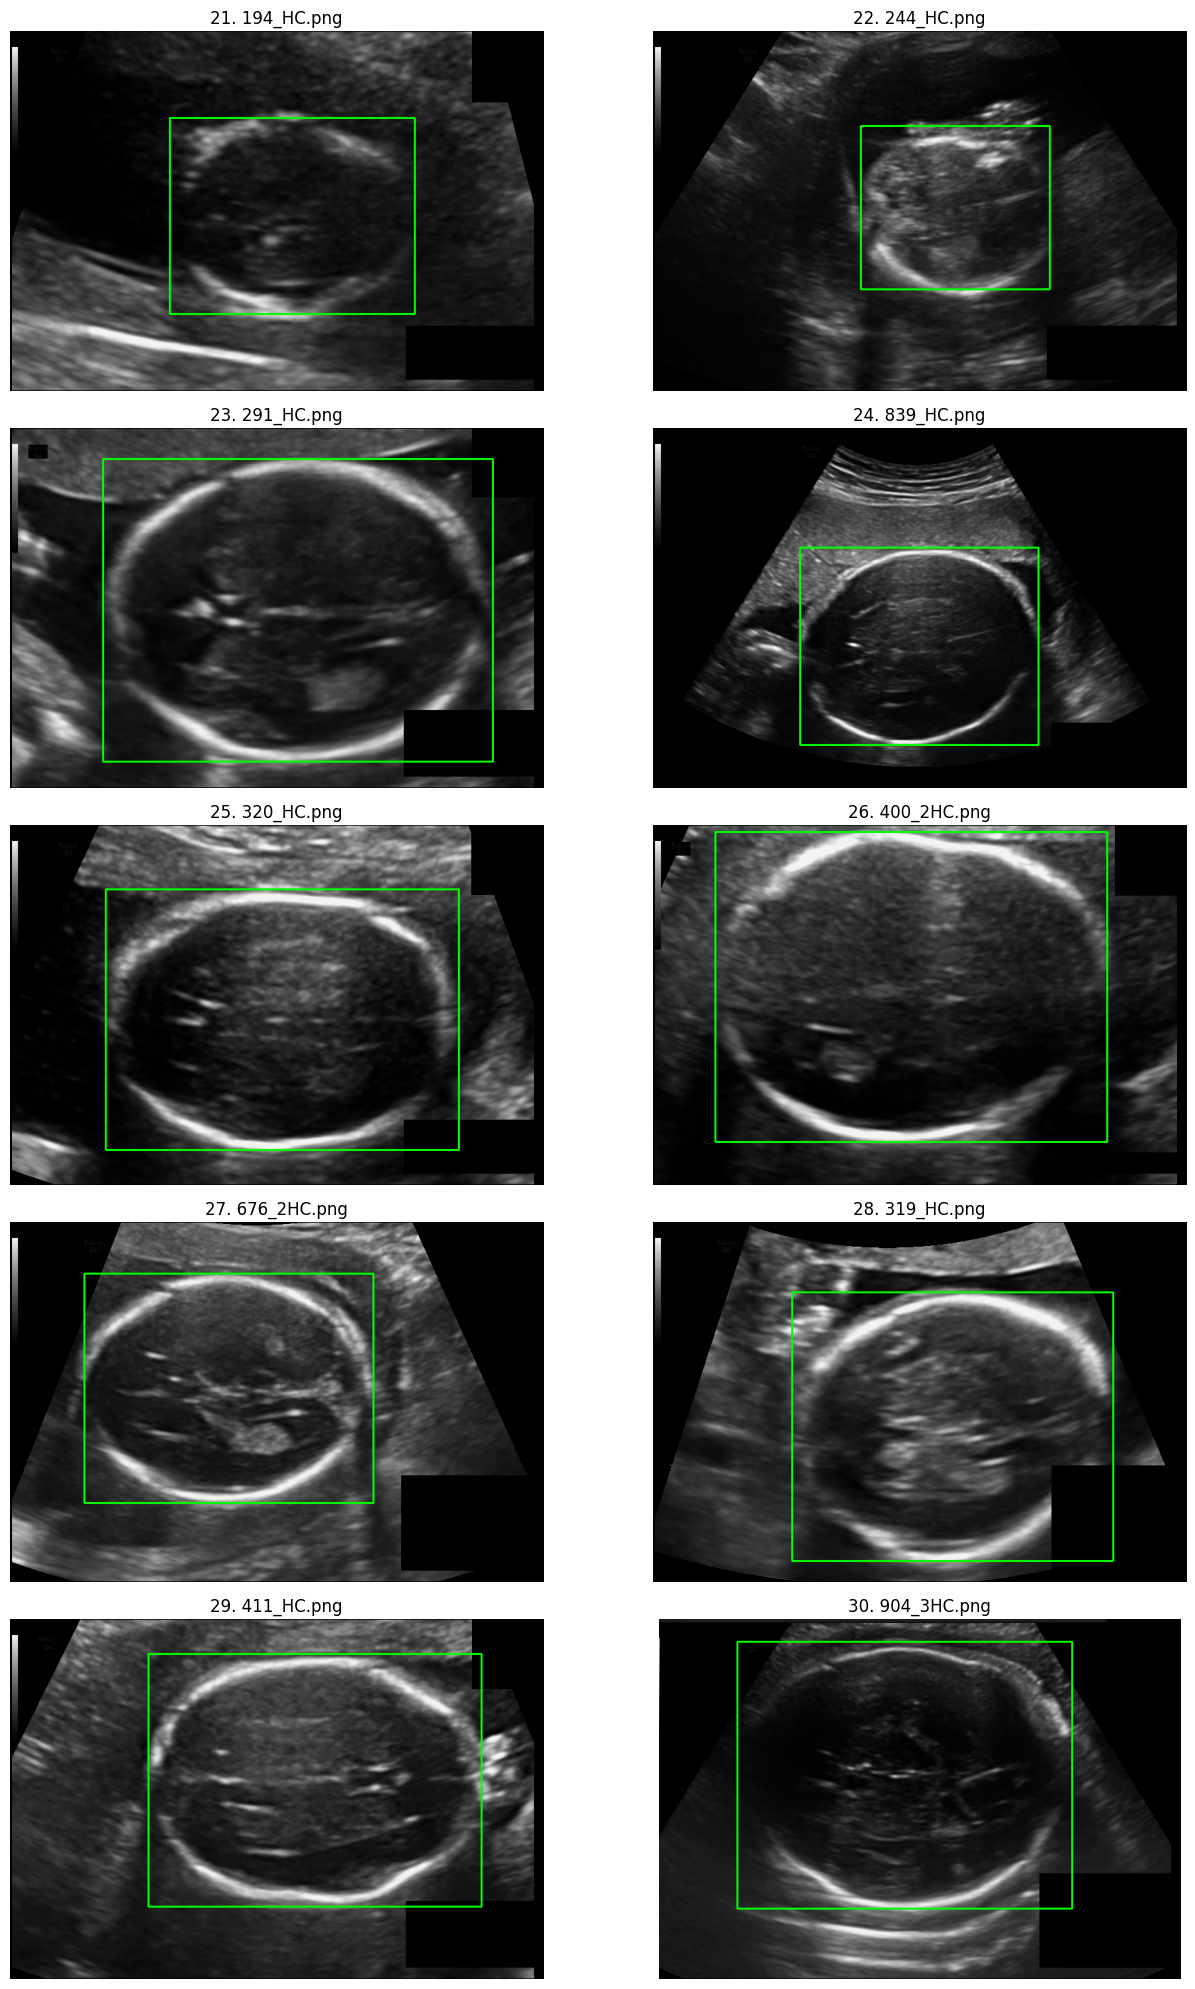

In [23]:

# Visual review: images 21 to 30

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, (ax, img_path) in enumerate(
    zip(axes.flat, review_samples[20:30]), start=21
):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]

    label_path = labels_dir / (img_path.stem + ".txt")
    values = label_path.read_text().split()
    xc, yc, bw, bh = map(float, values[1:])

    x1 = round((xc - bw / 2) * W)
    y1 = round((yc - bh / 2) * H)
    x2 = round((xc + bw / 2) * W)
    y2 = round((yc + bh / 2) * H)

    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{i}. {img_path.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [25]:

import pandas as pd

review_report = pd.DataFrame({
    "image_name": [p.name for p in review_samples],
    "review_status": ["Needs review"] * len(review_samples),
    "notes": ["Pending final visual confirmation"] * len(review_samples)
})

review_report.to_csv(
    "/content/HC18_Visual_Review.csv",
    index=False
)

print("Review records:", len(review_report))
display(review_report.head(10))


Review records: 30


,image_name,review_status,notes
0,342_HC.png,Needs review,Pending final visual confirmation
1,498_HC.png,Needs review,Pending final visual confirmation
2,93_HC.png,Needs review,Pending final visual confirmation
3,216_HC.png,Needs review,Pending final visual confirmation
4,966_HC.png,Needs review,Pending final visual confirmation
5,924_HC.png,Needs review,Pending final visual confirmation
6,917_HC.png,Needs review,Pending final visual confirmation
7,56_HC.png,Needs review,Pending final visual confirmation
8,530_HC.png,Needs review,Pending final visual confirmation
9,434_HC.png,Needs review,Pending final visual confirmation


In [26]:

review_report["notes"] = (
    "Initial visual screening completed; "
    "no obvious box misplacement observed. "
    "Final confirmation pending."
)

review_report.to_csv(
    "/content/HC18_Visual_Review.csv",
    index=False
)

print("Review report saved!")
print("Total images reviewed initially:", len(review_report))
print(review_report["review_status"].value_counts())


Review report saved!
Total images reviewed initially: 30
review_status
Needs review    30
Name: count, dtype: int64


In [27]:

from google.colab import files

files.download("/content/HC18_Visual_Review.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>